In [5]:
# libraries import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# csv file load
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin-1")

# pehli 5 rows dekho
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
# rows aur columns ki sankhya
print(df.shape)

# column ke data types aur null values
df.info()

# missing values count
print(df.isnull().sum())

# duplicate rows count
print(df.duplicated().sum())

(9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 1

In [7]:
# date columns ko date type mein badlo
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# year aur month ke naye columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

# check karo
print(df[["Order Date", "Year", "Month"]].head())
print(df["Order Date"].dtype)

  Order Date  Year  Month
0 2016-11-08  2016     11
1 2016-11-08  2016     11
2 2016-06-12  2016      6
3 2015-10-11  2015     10
4 2015-10-11  2015     10
datetime64[ns]


In [8]:
# total sales aur profit
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

# total orders aur customers
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

# profit margin percent
profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Profit Margin %:", round(profit_margin, 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Profit Margin %: 12.47


In [4]:
import os
print(os.getcwd())
print(os.listdir("../data"))

g:\Sales-Data-Analysis\notebooks
['archive (1)', 'Sample - Superstore.csv']


In [9]:
# category wise sales aur profit
print(df.groupby("Category")[["Sales", "Profit"]].sum())

# region wise sales aur profit
print(df.groupby("Region")[["Sales", "Profit"]].sum())

# year wise sales
print(df.groupby("Year")["Sales"].sum())

# top 5 sub-category by profit
print(df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(5))

# loss wali bottom 3 sub-category
print(df.groupby("Sub-Category")["Profit"].sum().sort_values().head(3))

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481
               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489
Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Name: Profit, dtype: float64
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64


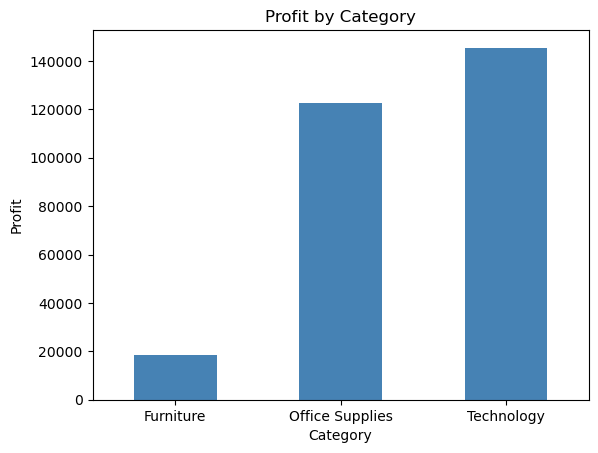

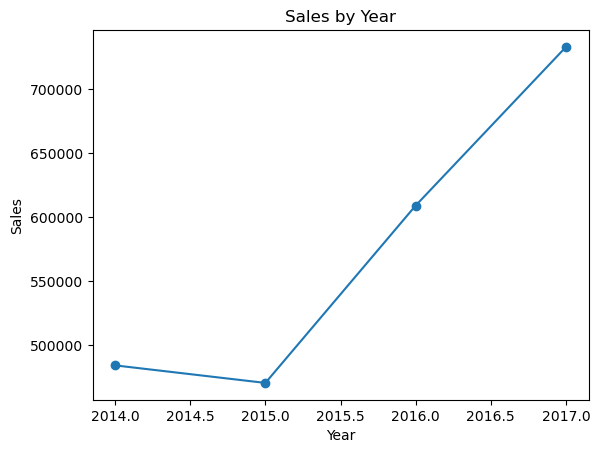

In [10]:
# category wise profit chart
df.groupby("Category")["Profit"].sum().plot(kind="bar", color="steelblue")
plt.title("Profit by Category")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.savefig("../screenshots/profit_by_category.png", bbox_inches="tight")
plt.show()

# year wise sales chart
df.groupby("Year")["Sales"].sum().plot(kind="line", marker="o")
plt.title("Sales by Year")
plt.ylabel("Sales")
plt.savefig("../screenshots/sales_by_year.png", bbox_inches="tight")
plt.show()

In [1]:
import pymysql
import sqlalchemy
print("ok")

ok


In [2]:
%pip install pymysql

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# mysql ki details
user = "root"
password = quote_plus("your_password")
host = "localhost"
database = "sales_db"

# mysql se connection
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}/{database}")

# column names mein space aur hyphen hatao
df_sql = df.copy()
df_sql.columns = df_sql.columns.str.replace(" ", "_").str.replace("-", "_")

# data ko superstore table mein daalo
df_sql.to_sql("superstore", engine, if_exists="replace", index=False)
print("done")

done


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# csv file load
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin-1")

# date columns ko date type mein badlo
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# year aur month ke naye columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

print(df.shape)

(9994, 23)
